# 02 - Feature engineering

Features are built in `src/features.py`. Transactions are grouped to one row per customer
before joining so loans don't get duplicated, and the columns only known after the
decision (approval_status, approved_amount, decision_date, disbursed_flag) are dropped.

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
from features import get_data, num_cols, cat_cols

In [2]:
df = get_data()
df = df[df["loan_default"].notna()]
df["loan_default"] = df["loan_default"].astype(int)
print(df.shape)
print(len(num_cols), "numeric,", len(cat_cols), "categorical")

(3403, 51)
28 numeric, 5 categorical


In [3]:
df[num_cols].isna().sum().sum()

np.int64(0)

No missing values left. `tenure_years` is clipped at 0 because 418 loans are dated before
the customer's `customer_since` date.

## New features vs default

In [4]:
new = ["debt_to_limit", "loan_to_income", "tenure_years", "net_cash_flow",
       "emi_outflow", "avg_balance", "inflow_outflow_ratio", "txn_count"]
df[new + ["loan_default"]].corr()["loan_default"].drop("loan_default").sort_values()

avg_balance            -0.155144
emi_outflow            -0.089029
tenure_years           -0.020332
net_cash_flow          -0.001592
txn_count               0.006865
inflow_outflow_ratio    0.006972
debt_to_limit           0.087700
loan_to_income          0.175499
Name: loan_default, dtype: float64

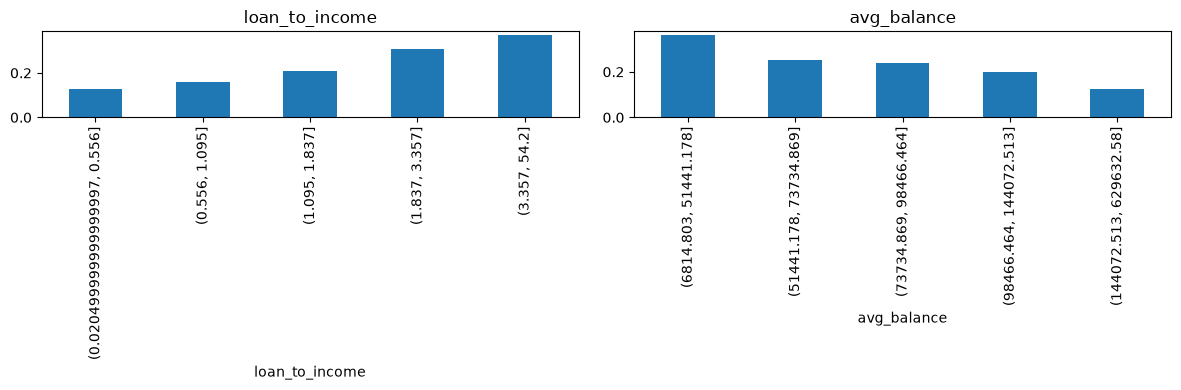

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["loan_to_income", "avg_balance"]):
    df.groupby(pd.qcut(df[col], 5), observed=True)["loan_default"].mean().plot.bar(ax=ax, title=col)
plt.tight_layout()

`loan_to_income` and `avg_balance` are the useful ones (lower balance -> more defaults).
The other transaction features are weak on their own, keeping them in for now.

## Repeat borrowers

In [6]:
df["customer_id"].value_counts().value_counts().sort_index()

count
1    1500
2     583
3     176
4      43
5       5
6       2
Name: count, dtype: int64

Around 800 customers have more than one loan with the exact same bureau and transaction
features, so the train/test split is grouped by customer.

Also the bureau data is from June 2024 and transactions are Jan-Jun 2024, so for older
loans these come from after the loan was given. Need to mention this in the model card.